In [ ]:
!pip install transformers==4.44.2 datasets==2.21.0 accelerate==0.34.2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 10.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 7.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 7.5 MB/s  0:00:00
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
Failed to build tokenizers
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> t

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import f1_score

import tensorflow as tf

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Reviews.csv")

print(df.shape)
df.head()

Saving Reviews.csv to Reviews.csv
(568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [ ]:
df = df[['Text', 'Score']]

df = df.dropna()

def sentiment(score):
    if score <= 2:
        return 0
    elif score == 3:
        return 1
    else:
        return 2

df['Sentiment'] = df['Score'].apply(sentiment)

df = df[['Text', 'Sentiment']]

print(df.head())
print(df['Sentiment'].value_counts())

                                                Text  Sentiment
0  I have bought several of the Vitality canned d...          2
1  Product arrived labeled as Jumbo Salted Peanut...          0
2  This is a confection that has been around a fe...          2
3  If you are looking for the secret ingredient i...          0
4  Great taffy at a great price.  There was a wid...          2
Sentiment
2    443777
0     82037
1     42640
Name: count, dtype: int64


In [ ]:
df = df.groupby('Sentiment').sample(
    n=1500,
    random_state=42
)

print(df['Sentiment'].value_counts())
print(df.shape)

Sentiment
0    1500
1    1500
2    1500
Name: count, dtype: int64
(4500, 2)


In [ ]:
X = df['Text']
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 3600
Testing data: 900


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer_lstm = Tokenizer(num_words=10000, oov_token="<OOV>")

tokenizer_lstm.fit_on_texts(X_train)

X_train_seq = tokenizer_lstm.texts_to_sequences(X_train)
X_test_seq = tokenizer_lstm.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=100, padding='post'
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=100, padding='post'
)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

lstm_model = Sequential([
    Embedding(10000, 64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = lstm_model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.3524 - loss: 1.0983 - val_accuracy: 0.3611 - val_loss: 1.0985
Epoch 2/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.3830 - loss: 1.0854 - val_accuracy: 0.3264 - val_loss: 1.1000
Epoch 3/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 9s 57ms/step - accuracy: 0.4451 - loss: 1.0168 - val_accuracy: 0.3667 - val_loss: 1.1384
Epoch 4/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.5410 - loss: 0.9148 - val_accuracy: 0.4111 - val_loss: 1.1903
Epoch 5/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.5385 - loss: 0.8790 - val_accuracy: 0.4153 - val_loss: 1.1200


In [ ]:
lstm_pred = np.argmax(
    lstm_model.predict(X_test_pad),
    axis=1
)

lstm_accuracy = accuracy_score(y_test, lstm_pred)

print("LSTM Accuracy:", lstm_accuracy)

print(classification_report(
    y_test,
    lstm_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
LSTM Accuracy: 0.36666666666666664
              precision    recall  f1-score   support

    Negative       0.41      0.10      0.16       300
     Neutral       0.51      0.12      0.20       300
    Positive       0.35      0.88      0.50       300

    accuracy                           0.37       900
   macro avg       0.42      0.37      0.29       900
weighted avg       0.42      0.37      0.29       900



In [ ]:
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

from datasets import Dataset
import torch

In [ ]:
model_name = "bert-base-uncased"

bert_tokenizer = BertTokenizer.from_pretrained(model_name)

bert_model = BertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
train_data = pd.DataFrame({
    'text': X_train,
    'labels': y_train
})

test_data = pd.DataFrame({
    'text': X_test,
    'labels': y_test
})

train_dataset = Dataset.from_pandas(train_data)
test_dataset = Dataset.from_pandas(test_data)

In [ ]:
def tokenize_function(examples):
    return bert_tokenizer(
        examples['text'],
        padding='max_length',
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

Map:   0%|          | 0/3600 [00:00<?, ? examples/s]

Map:   0%|          | 0/900 [00:00<?, ? examples/s]

In [ ]:
training_args = TrainingArguments(
    output_dir='./bert_results',
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    report_to='none',
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=bert_tokenizer
)

In [19]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,No log,0.669352


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,No log,0.669352
2,0.749121,0.767548


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=900, training_loss=0.6081847805447048, metrics={'train_runtime': 11223.9492, 'train_samples_per_second': 0.641, 'train_steps_per_second': 0.08, 'total_flos': 473604151910400.0, 'train_loss': 0.6081847805447048, 'epoch': 2.0})

In [ ]:
 predictions = trainer.predict(test_dataset)

bert_pred = np.argmax(
    predictions.predictions,
    axis=1
)

bert_accuracy = accuracy_score(y_test, bert_pred)

print("BERT Accuracy:", bert_accuracy)

print(classification_report(
    y_test,
    bert_pred,
    target_names=['Negative', 'Neutral', 'Positive']
))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [21]:
results = pd.DataFrame({
    'Model': ['LSTM', 'BERT'],
    'Accuracy': [
        lstm_accuracy,
        bert_accuracy
    ],
    'F1 Score': [
        f1_score(y_test, lstm_pred, average='macro'),
        f1_score(y_test, bert_pred, average='macro')
    ]
})

print(results)

  Model  Accuracy  F1 Score
0  LSTM  0.366667  0.286100
1  BERT  0.692222  0.690806


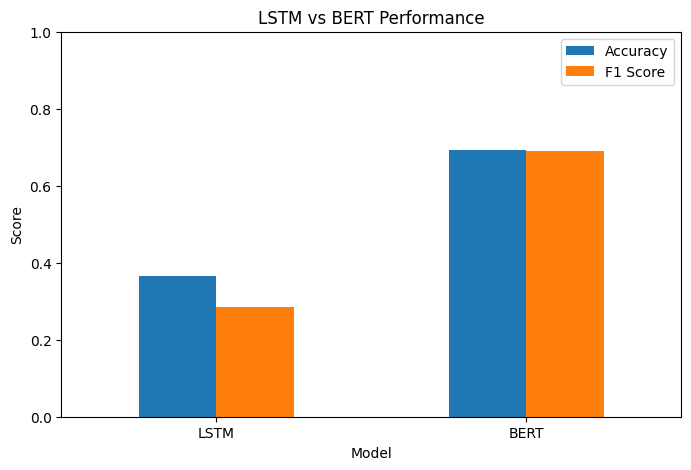

In [22]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("LSTM vs BERT Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

In [23]:
review = ["This product is amazing and I really love it"]

inputs = bert_tokenizer(
    review,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128
)

inputs = {
    key: value.to(bert_model.device)
    for key, value in inputs.items()
}

with torch.no_grad():
    output = bert_model(**inputs)

prediction = torch.argmax(output.logits, dim=1).item()

labels = ['Negative', 'Neutral', 'Positive']

print("Predicted Sentiment:", labels[prediction])

Predicted Sentiment: Positive


In [24]:

trainer.save_model("./amazon_bert_model")
bert_tokenizer.save_pretrained("./amazon_bert_model")

lstm_model.save("amazon_lstm_model.keras")

print("Models saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Models saved successfully!
